# 14 — Targeted robustness of the FX-only time-variation model

Keep **constant world and US/Hungarian local prices, time-varying FX prices, corrected FX means,
zero equity alphas**, both USD/EUR perspectives and both retained covariance models. All cases retain
**321 observed months, 2000-01 through 2026-09**, from the same sealed snapshot. Run notebook 13 first,
then **Run All** in the existing Miniconda **base** kernel. There are no downloads or API keys.

Fix the sensitivity set before fitting. Source returns, prices and CPI indices are never edited or
interpolated. All monthly observations remain in the GARCH recursion. Some stress checks give selected
calendar dates zero likelihood weight; their observed innovations still affect subsequent covariance
states. They are influence checks, not samples with those events removed. The small weighted-objective
extension is [fx_robustness.py](fx_robustness.py); earlier engines and outputs stay unchanged.

In [1]:
SNAPSHOT="data/fixed_2026-11-13/from_2000-01"
UPSTREAM="output/13_time_varying_FX_only/fixed_2026-11-13/2000-01_2026-09/constant_world_local"
COVARIANCE_MODELS=["scalar11","grouped21"]
VARIANTS=["baseline","lag3","gap_level","no_regime","no_US_CPI","CPI_terms0","block_2008_09","block_2020","block_2022_23"]
HAC_LAGS=[0,3,6,12]
TEST_LAGS=12
MAX_ITER=2800
SE_STEP_TOL=.01
REUSE_FITS=True
MODEL_VERSION="FX_targeted_checks_v1"
BLOCKS={"block_2008_09":("2008-01","2009-12"),"block_2020":("2020-01","2020-12"),"block_2022_23":("2022-01","2023-12")}

from pathlib import Path
from io import BytesIO
import hashlib,importlib,importlib.metadata,json,os,platform,sys,warnings
ROOT=Path.cwd()
os.environ.setdefault("MPLCONFIGDIR",str(ROOT/".cache"/"matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from packaging.version import Version
if Version(importlib.metadata.version("statsmodels"))<Version("0.15.0"):raise RuntimeError("Update statsmodels to 0.15.0 and restart the same base kernel.")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__!=importlib.metadata.version("statsmodels"):
    raise RuntimeError("Restart the same kernel to discard old statsmodels imports.")
from statsmodels.tsa.stattools import adfuller,kpss
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests
from IPython.display import display,Markdown
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import pricing_robustness as base
import covariance_robustness as covariance
import local_risk_pricing as model
import fx_robustness as stress
importlib.reload(base);importlib.reload(covariance);importlib.reload(model);importlib.reload(stress)
versions={p:importlib.metadata.version(p) for p in ["numpy","pandas","scipy","statsmodels","matplotlib"]}
engine_hashes={p:hashlib.sha256((ROOT/p).read_bytes()).hexdigest() for p in ["pricing_robustness.py","covariance_robustness.py","local_risk_pricing.py","pricing_error_tests.py","fx_robustness.py"]}
print("Python:",sys.executable);print("Packages:",versions)
allowed=["baseline","lag3","gap_level","no_regime","no_US_CPI","CPI_terms0",*BLOCKS]
if not VARIANTS or VARIANTS[0]!="baseline" or len(set(VARIANTS))!=len(VARIANTS) or any(v not in allowed for v in VARIANTS):raise ValueError("Start with baseline and choose distinct listed checks.")
if not COVARIANCE_MODELS or len(set(COVARIANCE_MODELS))!=len(COVARIANCE_MODELS) or any(m not in ["scalar11","grouped21"] for m in COVARIANCE_MODELS):raise ValueError("Use the retained covariance models.")
if not HAC_LAGS or 0 not in HAC_LAGS or len(set(HAC_LAGS))!=len(HAC_LAGS) or any(type(h)!=int or h<0 for h in HAC_LAGS):raise ValueError("Include zero and distinct nonnegative integer HAC lags.")
pd.set_option("display.max_columns",20);pd.set_option("display.max_rows",50);pd.options.display.float_format=lambda x:f"{x:.6g}"
plt.rcParams.update({"figure.dpi":120,"font.size":10,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.16})
source,upstream=ROOT/SNAPSHOT,ROOT/UPSTREAM
manifest=json.loads((source/"manifest.json").read_text());raw=(source/"dataset.csv").read_bytes()
if not manifest.get("sealed") or hashlib.sha256(raw).hexdigest()!=manifest["exports"]["dataset.csv"]:raise ValueError("Frozen dataset checksum differs.")
data=pd.read_csv(BytesIO(raw),index_col=0,float_precision="round_trip");data.index=pd.PeriodIndex(data.index,freq="M",name="month")
if not data.index.equals(pd.period_range(data.index[0],data.index[-1],freq="M")):raise ValueError("Discontinuous working months.")
if max(HAC_LAGS)>=len(data):raise ValueError("HAC bandwidth exceeds the sample.")
upstream_hashes,chain_hashes,conditioning_hashes,raw_hashes={},{},{},{}
def upstream_bytes(name):
    content=(upstream/name).read_bytes();upstream_hashes[name]=hashlib.sha256(content).hexdigest();return content
prior=json.loads(upstream_bytes("estimation_manifest.json"))
if (prior["source_dataset_sha256"]!=manifest["exports"]["dataset.csv"] or prior["first"]!=str(data.index[0]) or prior["last"]!=str(data.index[-1]) or prior["observations"]!=len(data) or prior["equity_alphas"]!="fixed zero" or prior["FX_means"]!="corrected pricing equations"):
    raise ValueError("Notebook 13 sample/mean restrictions differ.")
for name,digest in prior["engines"].items():
    if engine_hashes[name]!=digest:raise ValueError("An upstream engine changed.")
spec=prior["world_FX_instruments"];GLOBAL=spec["world"]
if spec["HUF_inflation"]!="change" or spec["other_inflation"]!="level" or not spec["HUF_regime"]:raise ValueError("Expected the audited change/level/regime baseline.")
ledger=prior
while "instrument_normalizers.csv" not in ledger.get("conditioning_file_sha256",{}):
    path=ROOT/ledger["upstream"]/"estimation_manifest.json";content=path.read_bytes();digest=hashlib.sha256(content).hexdigest()
    if digest!=ledger["upstream_file_sha256"]["estimation_manifest.json"]:raise ValueError("Provenance chain changed.")
    chain_hashes[str(path.relative_to(ROOT))]=digest;ledger=json.loads(content)
conditioning_root=ROOT/prior["conditioning_root"]
def conditioning_bytes(name):
    content=(conditioning_root/name).read_bytes();digest=hashlib.sha256(content).hexdigest()
    if digest!=ledger["conditioning_file_sha256"][name]:raise ValueError(f"Conditioning checksum differs: {name}")
    if name in prior["conditioning_file_sha256"] and digest!=prior["conditioning_file_sha256"][name]:raise ValueError("Conditioning vintages differ.")
    conditioning_hashes[name]=digest;return content
normalizers=pd.read_csv(BytesIO(conditioning_bytes("instrument_normalizers.csv")),index_col=[0,1,2],float_precision="round_trip").sort_index()
prior_quality=pd.read_csv(BytesIO(conditioning_bytes("conditioning_quality_flags.csv")),index_col=[0,1])
old_summary=pd.read_csv(BytesIO(upstream_bytes("fit_summary.csv")),index_col=0,float_precision="round_trip")
archived,samples,references={}, {}, {}
for currency in ["USD","EUR"]:
    archived[currency]={}
    for label in ["H","O"]:
        z=pd.read_csv(BytesIO(conditioning_bytes(f"conditioning_{currency.lower()}_{label}.csv")),index_col=0,float_precision="round_trip")
        if not pd.PeriodIndex(z.index,freq="M").equals(data.index):raise ValueError("Conditioning months differ.")
        archived[currency][label]=z
    equity=data[[f"rx_{a}_{currency.lower()}" for a in ["world","us","hu"]]].to_numpy()*100
    fx=np.c_[data[f"fx_huf_{currency.lower()}"]*100,data["fx_eur_usd"]*100*(1 if currency=="USD" else -1)]
    samples[currency]=np.c_[equity,fx]
    for name in COVARIANCE_MODELS:
        key=f"{currency}_{name}_FX"
        with np.load(BytesIO(upstream_bytes(f"parameters_{key}.npz")),allow_pickle=False) as a:references[(currency,name)]={k:a[k].copy() for k in a.files}
        if not np.array_equal(references[(currency,name)]["equity_alphas"],np.zeros(3)):raise ValueError("Reference alphas are not zero.")
OUT=ROOT/"output"/"14_FX_targeted_robustness"/source.parent.name/f"{data.index[0]}_{data.index[-1]}"/"targeted_set"
OUT.mkdir(parents=True,exist_ok=True)

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8'}


## 1. Reconstruct inputs and fix the targeted checks

| Check | Change from the FX-only baseline |
|---|---|
| `lag3` | Both inflation-gap conditioners lagged three months; use frozen pre-sample history |
| `gap_level` | HUF gap level replaces its change at lag 2; exploratory because of persistence |
| `no_regime` | Remove the HUF floating-regime predictor |
| `no_US_CPI` | Remove all direct FX-price inflation predictors involving US CPI, for the whole sample |
| `CPI_terms0` | Zero joint likelihood weight at dates whose baseline predictors use the carried US annual rate |
| `block_2008_09` | Zero likelihood weight for 2008-01 through 2009-12 |
| `block_2020` | Zero likelihood weight for 2020-01 through 2020-12 |
| `block_2022_23` | Zero likelihood weight for 2022-01 through 2023-12 |

Changing publication lag must not lose January 2000: reconstruct from sealed raw CPI/HICP history,
not by shifting the 321-row exported design and dropping its first month. Repeat exactly the original
one-month **US annual-inflation-rate** carry for conditioning; never fill a CPI index or return.
A longer lag is a timing sensitivity, not proof of real-time information availability: the frozen
historical series may contain revisions.

`no_US_CPI` removes direct dependence on carried predictors but also removes valid US-inflation
information elsewhere. In EUR, the HUF gap is EA-minus-Hungary and remains; the US/EA predictor is
removed from the other FX equation. `CPI_terms0` is a complementary influence check and **does not
remove propagated effects** of flagged-month innovations. The same is true of the calendar-block
checks: observed crisis returns still update the GARCH state. No crisis-free-sample claim is made.

Standardize designs on the same full 321 months in every case, including weighted checks. Audit
rank/conditioning on both full and likelihood-scored dates before fitting. Keep all scenarios,
including non-rejections and numerical failures, rather than selecting by their p-values.

In [2]:
# Repeat notebook 07's raw-data inflation calculation, retaining pre-sample observations.
def raw_bytes(name):
    content=(source/"raw"/name).read_bytes();digest=hashlib.sha256(content).hexdigest()
    if digest!=manifest["sources"][name]["sha256"]:raise ValueError(f"Frozen raw checksum differs: {name}")
    raw_hashes[name]=digest;return content
fred=pd.read_csv(BytesIO(raw_bytes("fred.csv")),index_col=0,na_values=".",float_precision="round_trip")
fred.index=pd.PeriodIndex(fred.index,freq="M");fred=fred.reindex(pd.period_range(fred.index.min(),fred.index.max(),freq="M"))
rebuilt_global=pd.DataFrame({GLOBAL[0]:fred["TB3MS"].diff().shift(1),GLOBAL[1]:(fred["GS10"]-fred["TB3MS"]).diff().shift(1),GLOBAL[2]:(fred["BAA"]-fred["AAA"]).shift(1)}).loc[data.index]
np.testing.assert_allclose(rebuilt_global,data[GLOBAL],atol=1e-12,rtol=0)
hj=json.loads(raw_bytes("eurostat_hicp.json"))
if hj["id"]!=["freq","unit","coicop18","geo","time"] or hj["size"][:3]!=[1,1,1]:raise ValueError("Unexpected HICP layout.")
values=np.full(int(np.prod(hj["size"])),np.nan)
for position,value in hj["value"].items():values[int(position)]=value
values=values.reshape(hj["size"])[0,0,0];cat=hj["dimension"]
hicp_dates=sorted(cat["time"]["category"]["index"],key=cat["time"]["category"]["index"].get)
hicp=pd.DataFrame({c:values[cat["geo"]["category"]["index"][c]] for c in ["HU","EA"]},index=pd.PeriodIndex(hicp_dates,freq="M"))
full_index=pd.period_range(max(hicp.index.min(),fred.index.min()),data.index.max(),freq="M")
cpi=pd.concat([fred["CPIAUCNS"].rename("US"),hicp],axis=1).reindex(full_index)
annual=cpi.pct_change(12,fill_method=None)*100;carry_limit=int(manifest["max_us_inflation_carry_months"])
us=annual["US"].ffill(limit=carry_limit) if carry_limit else annual["US"]
carried=annual["US"].isna() & us.notna()
gaps=pd.DataFrame({"US_HU":us-annual["HU"],"EA_HU":annual["EA"]-annual["HU"],"US_EA":us-annual["EA"]})
np.testing.assert_allclose(gaps.shift(2).loc[data.index,["US_HU","EA_HU"]],data[["inflation_gap_usd_lag2_pp","inflation_gap_eur_lag2_pp"]],atol=1e-12,rtol=0)
np.testing.assert_array_equal(carried.shift(2,fill_value=False).loc[data.index].astype(int),data["flag_us_inflation_carried_lag2"].astype(int))

features,designs,columns,weights_by,quality_by={}, {}, {}, {}, {}
audit_rows,normalizer_rows,quality_rows,inflation_rows=[],[],[],[]
for currency,gap in [("USD","US_HU"),("EUR","EA_HU")]:
    features[currency],designs[currency],columns[currency],weights_by[currency],quality_by[currency]={},{},{},{},{}
    for variant in VARIANTS:
        lag=3 if variant=="lag3" else 2;form="level" if variant=="gap_level" else "change"
        H=data[GLOBAL].copy();O=data[GLOBAL].copy()
        hn=f"HUF_inflation_gap_{form}_lag{lag}_pp";on=f"other_inflation_gap_level_lag{lag}_pp"
        H[hn]=(gaps.diff() if form=="change" else gaps).shift(lag).loc[data.index,gap]
        H["floating_regime_known"]=data["floating_regime_known"]
        O[on]=(1 if currency=="USD" else -1)*gaps.shift(lag).loc[data.index,"US_EA"]
        hflag=carried.shift(lag,fill_value=False)
        if form=="change":hflag=hflag|carried.shift(lag+1,fill_value=False)
        hflag=hflag.loc[data.index] if currency=="USD" else pd.Series(False,index=data.index)
        oflag=carried.shift(lag,fill_value=False).loc[data.index]
        if variant=="no_regime":H=H.drop(columns="floating_regime_known")
        if variant=="no_US_CPI":
            O=O.drop(columns=on);oflag=pd.Series(False,index=data.index)
            if currency=="USD":H=H.drop(columns=hn);hflag=pd.Series(False,index=data.index)
        w=np.ones(len(data))
        if variant=="CPI_terms0":w[(hflag|oflag).to_numpy()]=0
        if variant in BLOCKS:
            start,end=BLOCKS[variant];w[(data.index>=pd.Period(start,freq="M"))&(data.index<=pd.Period(end,freq="M"))]=0
        weights_by[currency][variant]=w;quality_by[currency][variant]=pd.DataFrame({"H_uses_carried_US_rate":hflag,"O_uses_carried_US_rate":oflag},index=data.index)
        features[currency][variant]={"H":H,"O":O};designs[currency][variant]={};columns[currency][variant]={}
        for label,frame in features[currency][variant].items():
            mean,sd=frame.mean(),frame.std(ddof=1)
            if not np.isfinite(frame).all().all() or not sd.gt(0).all():raise ValueError("Missing/constant stress predictor.")
            z=np.c_[np.ones(len(data)),((frame-mean)/sd).to_numpy()]
            if variant in ["baseline","CPI_terms0",*BLOCKS]:
                np.testing.assert_allclose(z,archived[currency][label],atol=1e-12,rtol=0);z=archived[currency][label].to_numpy().copy()
            if np.linalg.matrix_rank(z)!=z.shape[1] or np.linalg.matrix_rank(z[w>0])!=z.shape[1]:raise ValueError("Rank-deficient stress design.")
            designs[currency][variant][label]=z;columns[currency][variant][label]=["constant"]+list(frame.columns)
            audit_rows.append({"perspective":currency,"variant":variant,"price":label,"state_months":len(data),"scored_months":int(w.sum()),"columns":z.shape[1],"rank_full":np.linalg.matrix_rank(z),"rank_scored":np.linalg.matrix_rank(z[w>0]),"condition_full":np.linalg.cond(z),"condition_scored":np.linalg.cond(z[w>0]),"max_VIF":max(variance_inflation_factor(z,j) for j in range(1,z.shape[1]))})
            normalizer_rows.extend({"perspective":currency,"variant":variant,"price":label,"instrument":name,"mean":mean[name],"sd":sd[name]} for name in frame)
            for name in frame:
                if "inflation_gap" in name and variant in ["baseline","lag3","gap_level"]:
                    s=frame[name];a=adfuller(s,maxlag=12,regression="c",autolag="AIC",result_object=False)
                    with warnings.catch_warnings(record=True) as caught:
                        warnings.simplefilter("always");k=kpss(s,regression="c",nlags="auto",result_object=False)
                    note="at least 0.10" if k[1]==.1 and caught else "at most 0.01" if k[1]==.01 and caught else "reported p-value"
                    inflation_rows.append({"perspective":currency,"variant":variant,"price":label,"instrument":name,"AR1":s.autocorr(),"ADF_p":a[1],"KPSS_p":k[1],"KPSS_p_note":note})
        quality_rows.extend({"perspective":currency,"variant":variant,"month":str(month),"H_uses_carried_US_rate":bool(hflag.loc[month]),"O_uses_carried_US_rate":bool(oflag.loc[month]),"likelihood_weight":w[i]} for i,month in enumerate(data.index))
    for label,column in [("H","HUF_inflation_uses_carried_US_rate"),("O","other_inflation_uses_carried_US_rate")]:np.testing.assert_array_equal(quality_by[currency]["baseline"].iloc[:,0 if label=="H" else 1],prior_quality.loc[currency,column].astype(bool))
design_audit=pd.DataFrame(audit_rows);normalizer_audit=pd.DataFrame(normalizer_rows);quality_audit=pd.DataFrame(quality_rows);inflation_audit=pd.DataFrame(inflation_rows)
display(design_audit);display(inflation_audit);display(quality_audit[(quality_audit["likelihood_weight"]==0)|(quality_audit["H_uses_carried_US_rate"]|quality_audit["O_uses_carried_US_rate"])].groupby(["perspective","variant"]).size().rename("flagged_or_unscored_months"))

,perspective,variant,price,state_months,scored_months,columns,rank_full,rank_scored,condition_full,condition_scored,max_VIF
0,USD,baseline,H,321,321,6,6,6,1.87417,1.87417,1.43318
1,USD,baseline,O,321,321,5,5,5,1.9049,1.9049,1.43181
2,USD,lag3,H,321,321,6,6,6,1.86826,1.86826,1.43181
3,USD,lag3,O,321,321,5,5,5,1.86782,1.86782,1.42072
4,USD,gap_level,H,321,321,6,6,6,1.8337,1.8337,1.40529
5,USD,gap_level,O,321,321,5,5,5,1.9049,1.9049,1.43181
6,USD,no_regime,H,321,321,5,5,5,1.85457,1.85457,1.41968
7,USD,no_regime,O,321,321,5,5,5,1.9049,1.9049,1.43181
8,USD,no_US_CPI,H,321,321,5,5,5,1.80885,1.80885,1.39336
9,USD,no_US_CPI,O,321,321,4,4,4,1.79186,1.79186,1.38055


,perspective,variant,price,instrument,AR1,ADF_p,KPSS_p,KPSS_p_note
0,USD,baseline,H,HUF_inflation_gap_change_lag2_pp,0.551572,3.84579e-10,0.1,at least 0.10
1,USD,baseline,O,other_inflation_gap_level_lag2_pp,0.926314,0.0087031,0.1,at least 0.10
2,USD,lag3,H,HUF_inflation_gap_change_lag3_pp,0.552023,3.44965e-10,0.1,at least 0.10
3,USD,lag3,O,other_inflation_gap_level_lag3_pp,0.926647,0.00904562,0.1,at least 0.10
4,USD,gap_level,H,HUF_inflation_gap_level_lag2_pp,0.978597,0.10761,0.1,at least 0.10
5,USD,gap_level,O,other_inflation_gap_level_lag2_pp,0.926314,0.0087031,0.1,at least 0.10
6,EUR,baseline,H,HUF_inflation_gap_change_lag2_pp,0.420178,1.84255e-09,0.1,at least 0.10
7,EUR,baseline,O,other_inflation_gap_level_lag2_pp,0.926314,0.0087031,0.1,at least 0.10
8,EUR,lag3,H,HUF_inflation_gap_change_lag3_pp,0.420654,1.49764e-09,0.1,at least 0.10
9,EUR,lag3,O,other_inflation_gap_level_lag3_pp,0.926647,0.00904562,0.1,at least 0.10


perspective  variant      
EUR          CPI_terms0        1
             baseline          1
             block_2008_09    25
             block_2020       13
             block_2022_23    25
             gap_level         1
             lag3              1
             no_regime         1
USD          CPI_terms0        2
             baseline          2
             block_2008_09    26
             block_2020       14
             block_2022_23    26
             gap_level         1
             lag3              2
             no_regime         2
Name: flagged_or_unscored_months, dtype: int64

## 2. Verify weighted scores and the unchanged state recursion

Write $\ell_t$ for a joint five-series negative log likelihood, $g_t=\partial\ell_t/\partial\theta$
and $w_t\in\{0,1\}$ for the fixed calendar weight. Minimize

$$\boxed{Q_T(\theta)=\frac1T\sum_{t=1}^T w_t\ell_t(\theta),\quad T=321.}$$

The filter uses all $T$ observations before weights are applied. Its derivatives therefore include
how unscored-month residuals affect later states. The full-calendar score is $w_tg_t$, with zero
contributions retained at their original dates. The Hessian and score-HAC covariance use the same
$1/T$ normalization and calendar spacing. Do not concatenate the retained dates or compress scores
across gaps. All-ones weights must reproduce notebook 13, including its robust covariance.

The eight sensitivity definitions are fixed above; each changes only the stated instruments or
likelihood weights. Re-estimate all risk-price/covariance parameters. Boundary-constrained solutions
can be retained if their projected gradient converges, but their ordinary inference is withheld.

In [3]:
def make_case(currency,name,variant):
    pdsg={"W":np.ones((len(data),1)),"H":designs[currency][variant]["H"].copy(),"O":designs[currency][variant]["O"].copy(),"L":np.ones((len(data),1))}
    names={"W":["constant"],**columns[currency][variant],"L":["constant"]}
    y=samples[currency];w=weights_by[currency][variant].copy()
    return {"id":f"{currency}_{name}_{variant}","currency":currency,"name":name,"variant":variant,"y":y,"pdesign":pdsg,"columns":names,"scales":y.std(axis=0,ddof=1),"weights":w}
def args(case):return (case["y"],case["pdesign"],case["scales"],case["name"],case["weights"])
def map_theta(theta,old,new):
    ko=model.layout(old["pdesign"],old["name"])[0];kn=model.layout(new["pdesign"],new["name"])[0]
    out=np.r_[np.zeros(kn),theta[ko:]];out[1]=theta[1]
    oi,ni=model.price_indices(old["pdesign"]),model.price_indices(new["pdesign"])
    for label,positions in ni.items():
        for j,column in zip(positions,new["columns"][label]):
            if column in old["columns"][label]:out[j]=theta[oi[label][old["columns"][label].index(column)]]
    return out
checks=[]
for currency in ["USD","EUR"]:
    for name in COVARIANCE_MODELS:
        b=make_case(currency,name,"baseline");saved=references[(currency,name)];f=model.filter_model(saved["theta"],*args(b)[:-1])
        for new,old in [("H","H"),("mu","mu"),("errors","residuals"),("scores","scores")]:np.testing.assert_allclose(f[new],saved[old],atol=1e-8,rtol=1e-9)
        np.testing.assert_allclose(-f["losses"].sum(),old_summary.loc[f"{currency}_{name}_FX","loglik"],atol=1e-8,rtol=0)
        value,gradient=stress.objective(saved["theta"],*args(b));np.testing.assert_allclose(value,f["losses"].mean(),atol=0,rtol=0);np.testing.assert_allclose(gradient,f["scores"].mean(axis=0),atol=0,rtol=0)
        for variant in VARIANTS:
            case=make_case(currency,name,variant);probe=model.initial_theta(*args(case)[:-1])
            for positions in model.price_indices(case["pdesign"]).values():probe[positions[1:]]=np.linspace(.12,-.08,len(positions)-1)
            w=np.ones(35);w[8:11]=0
            sub=(case["y"][:35],{a:z[:35] for a,z in case["pdesign"].items()},case["scales"],name,w)
            analytic=stress.objective(probe,*sub)[1];numeric=base.numerical_gradient(lambda t:stress.objective(t,*sub)[0],probe)
            np.testing.assert_allclose(analytic,numeric,atol=5e-6,rtol=5e-5)
            checks.append({"perspective":currency,"covariance":name,"variant":variant,"parameters":len(probe),"gradient_error":np.max(np.abs(analytic-numeric))})
        altered=b["y"].copy();altered[9,3]+=1.
        full0=model.filter_model(saved["theta"],*args(b)[:-1]);full1=model.filter_model(saved["theta"],altered,b["pdesign"],b["scales"],name)
        assert not np.allclose(full0["H"][10],full1["H"][10])
        w=np.ones(len(data));w[9]=0
        assert abs(stress.objective(saved["theta"],b["y"],b["pdesign"],b["scales"],name,w)[0]-stress.objective(saved["theta"],altered,b["pdesign"],b["scales"],name,w)[0])>1e-8
display(pd.DataFrame(checks))

,perspective,covariance,variant,parameters,gradient_error
0,USD,scalar11,baseline,31,7.25938e-09
1,USD,scalar11,lag3,31,7.14748e-09
2,USD,scalar11,gap_level,31,7.18136e-09
3,USD,scalar11,no_regime,30,7.03369e-09
4,USD,scalar11,no_US_CPI,29,7.12217e-09
5,USD,scalar11,CPI_terms0,31,7.25938e-09
6,USD,scalar11,block_2008_09,31,7.25938e-09
7,USD,scalar11,block_2020,31,7.25938e-09
8,USD,scalar11,block_2022_23,31,7.25938e-09
9,USD,grouped21,baseline,38,6.41811e-09


## 3. Estimate the complete fixed sensitivity set

Baseline estimates are verified notebook 13 references. Each sensitivity uses a mapped baseline start
and an independent moment start. Require optimizer success and a small projected gradient; show raw
gradients too. A binding parameter limit is an audit finding and blocks ordinary tests. Fail if a
lower unconverged candidate remains. Cache keys include input arrays, weights, source hashes, exact
starts, engine versions and optimizer settings. `REUSE_FITS=False` re-estimates sensitivities.

In [4]:
fits,start_rows={},[]
for currency in ["USD","EUR"]:
    for name in COVARIANCE_MODELS:
        b=make_case(currency,name,"baseline")
        for variant in VARIANTS:
            case=make_case(currency,name,variant);key=case["id"];print(key,flush=True)
            if variant=="baseline":
                theta=references[(currency,name)]["theta"];case.update(theta=theta,filter=model.filter_model(theta,*args(case)[:-1]),origin="verified notebook 13")
                fits[key]=case;print("  verified upstream reference",flush=True);continue
            starts=[map_theta(references[(currency,name)]["theta"],b,case),model.initial_theta(*args(case)[:-1])]
            config={"version":MODEL_VERSION,"engines":engine_hashes,"source_sha256":manifest["exports"]["dataset.csv"],"case":key,
                "first":str(data.index[0]),"last":str(data.index[-1]),"state_months":len(data),"scored_months":int(case["weights"].sum()),"python":platform.python_version(),"packages":versions,
                "max_iter":MAX_ITER,"starts":["mapped baseline","independent moment"],"start_sha256":[hashlib.sha256(t.tobytes()).hexdigest() for t in starts],
                "upstream_sha256":upstream_hashes,"conditioning_sha256":conditioning_hashes,"raw_sha256":raw_hashes,"price_columns":case["columns"]}
            payload=json.dumps(config,sort_keys=True).encode()+case["y"].tobytes()+case["weights"].tobytes()+b"".join(case["pdesign"][a].tobytes() for a in ["W","H","O","L"])
            fingerprint=hashlib.sha256(payload).hexdigest();path=OUT/f"fit_{key}.json"
            cached=json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
            limits=model.bounds(case["pdesign"],name);candidate=np.asarray(cached["theta"]) if cached else np.array([]);record=None
            if candidate.shape==(len(limits),) and cached.get("fingerprint")==fingerprint and np.isfinite(candidate).all() and (candidate>=limits[:,0]).all() and (candidate<=limits[:,1]).all():
                value,gradient=stress.objective(candidate,*args(case));pg=stress.projected_gradient(candidate,gradient,limits)
                if abs(value-cached["mean_weighted_nll"])<1e-8 and np.max(np.abs(pg))<1e-4:record=cached;print("  verified cached fit",flush=True)
            if record is None:
                best,runs=stress.fit_starts(args(case),starts,maxiter=MAX_ITER)
                record={"fingerprint":fingerprint,"configuration":config,"theta":best.x.tolist(),"mean_weighted_nll":float(best.fun),"starts":runs}
                path.write_text(json.dumps(record,indent=2)+"\n")
            for row in record["starts"]:start_rows.append({"case":key,**row})
            theta=np.asarray(record["theta"]);case.update(theta=theta,filter=model.filter_model(theta,*args(case)[:-1]),origin="joint sensitivity re-estimation");fits[key]=case
starting_points=pd.DataFrame(start_rows);display(starting_points)

USD_scalar11_baseline


  verified upstream reference


USD_scalar11_lag3


  verified cached fit


USD_scalar11_gap_level


  verified cached fit


... (63 outputs left out)

  verified cached fit


EUR_grouped21_block_2022_23


  verified cached fit


,case,start,success,mean_weighted_nll,raw_gradient,projected_gradient,iterations,message
0,USD_scalar11_lag3,1,True,11.5881,1.71928e-06,1.71928e-06,194,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
1,USD_scalar11_lag3,2,True,11.5881,5.0705e-07,5.0705e-07,207,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
2,USD_scalar11_gap_level,1,True,11.5904,1.12094e-06,1.12094e-06,183,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
3,USD_scalar11_gap_level,2,True,11.5904,1.49998e-07,1.49998e-07,208,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
4,USD_scalar11_no_regime,1,True,11.5921,4.00755e-06,4.00755e-06,150,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
...,...,...,...,...,...,...,...,...
59,EUR_grouped21_block_2008_09,2,True,10.4455,1.2613e-06,1.2613e-06,306,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
60,EUR_grouped21_block_2020,1,True,11.0762,5.75705e-06,5.75705e-06,190,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
61,EUR_grouped21_block_2020,2,True,11.0762,1.24305e-07,1.24305e-07,319,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
62,EUR_grouped21_block_2022_23,1,True,10.6502,8.46996e-06,5.22293e-07,478,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...


## 4. Report uncertainty, component tests and full-path diagnostics

Compute the full joint Hessian from weighted scores. Use Bartlett HAC bandwidths **0, 3, 6, 12** on
the full 321-row score sequence $w_tg_t$, including zero-score dates at their calendar positions.
Use $A^{-1}S_LA^{-1}/T$, without a finite-sample multiplier. All-ones cases must reproduce notebook
13. Withhold ordinary inference for parameter bounds, bad curvature/conditioning or unstable price
SEs at two numerical differentiation steps. A converged boundary fit is not a regular result.

Test constancy of **all retained FX slopes** jointly; degrees of freedom change when predictors are
removed. Also show each currency's constancy and zero-price tests, with Holm adjustment across the
two currency blocks **within a case/bandwidth/test family**. This adjustment does not cover the
scenario search. A joint rejection alone does not establish variation in the HUF price separately.
Constancy and zero pricing remain distinct hypotheses.

Residual screens always use the **full 321-month path**, including dates with zero objective weight.
They are approximate diagnostics after estimating GARCH parameters. Do not interpret block-weighted
fits as samples without those returns or as forecast evaluations. Likelihoods/IC are not ranked
across different weight patterns; this notebook focuses on specification sensitivity, not a new model
selection contest. The persistent gap-level alternative remains exploratory (ADF unit-root null;
KPSS level-stationarity null).

In [5]:
fit_rows,test_rows,coefficient_rows,residual_rows,cross_rows,path_rows=[],[],[],[],[],[]
for key,case in fits.items():
    print("Uncertainty:",key,flush=True)
    theta,f=case["theta"],case["filter"];inf=stress.inference(theta,args(case),f,hac_lags=HAC_LAGS,se_step_tol=SE_STEP_TOL);case["inference"]=inf
    idx=model.price_indices(case["pdesign"]);value,gradient=stress.objective(theta,*args(case))
    limits=model.bounds(case["pdesign"],case["name"]);pg=stress.projected_gradient(theta,gradient,limits)
    labels=["World","US equity","Hungary equity","HUF FX",("EUR FX" if case["currency"]=="USD" else "USD FX")]
    marginal,cross=base.diagnostics(f,labels,TEST_LAGS)
    for column in ["LB_z_p","LB_z_squared_p","ARCH_LM_p"]:marginal[column.replace("_p","_holm_p")]=multipletests(marginal[column],method="holm")[1]
    cross["LB_product_holm_p"]=multipletests(cross["LB_product_p"],method="holm")[1]
    residual_rows.extend({"case":key,"series":label,**row.to_dict()} for label,row in marginal.iterrows());cross_rows.extend({"case":key,"pair":label,**row.to_dict()} for label,row in cross.iterrows())
    j=int(np.argmin(inf["distance_to_bounds"]));k=model.layout(case["pdesign"],case["name"])[0];bound_name="none"
    if inf["near_bound"]:
        if k<=j<k+15:
            ii,jj=list(zip(*base.TRI))[j-k];bound_name=f"normalised C[{ii+1},{jj+1}]"+(" log diagonal" if ii==jj else "")
        else:bound_name=f"parameter position {j}"
    fit_rows.append({"case":key,"perspective":case["currency"],"covariance":case["name"],"variant":case["variant"],"state_months":len(data),"scored_months":int(case["weights"].sum()),"parameters":len(theta),
        "weighted_objective_sum":value*len(data),"raw_gradient":np.max(np.abs(gradient)),"projected_gradient":np.max(np.abs(pg)),"near_bound":inf["near_bound"],"bound_parameter":bound_name,
        "Hessian_condition":inf["Hessian_condition"],"regular_all_lags":all(v["ready"] for v in inf["estimates"].values()),"mean_flags_full_path":int((marginal["LB_z_p"]<.05).sum()),
        "variance_flags_full_path":int(((marginal["LB_z_squared_p"]<.05)|(marginal["ARCH_LM_p"]<.05)).sum()),"cross_flags_full_path":int((cross["LB_product_p"]<.05).sum()),
        "variance_flags_holm_full_path":int(((marginal["LB_z_squared_holm_p"]<.05)|(marginal["ARCH_LM_holm_p"]<.05)).sum())})
    restrictions={"FX prices constant":np.r_[idx["H"][1:],idx["O"][1:]],"FX prices zero":np.r_[idx["H"],idx["O"]],
        "HUF price constant":idx["H"][1:],"Other FX price constant":idx["O"][1:],"HUF price zero":idx["H"],"Other FX price zero":idx["O"],
        "World price zero":idx["W"],"Hungarian local price zero":idx["L"],"Local prices jointly zero":np.r_[1,idx["L"]]}
    for lag,estimate in inf["estimates"].items():
        V=estimate["covariance"]
        if case["variant"]=="baseline" and estimate["ready"]:np.testing.assert_allclose(V,references[(case["currency"],case["name"])][f"covariance_HAC{lag}"],atol=2e-6,rtol=2e-6)
        rows={label:base.wald(theta,V,positions) for label,positions in restrictions.items()};adjusted={}
        for pair in [("HUF price constant","Other FX price constant"),("HUF price zero","Other FX price zero")]:
            p=[rows[label]["robust_p_value"] for label in pair]
            correction=multipletests(p,method="holm")[1] if np.isfinite(p).all() else [np.nan,np.nan]
            adjusted.update(dict(zip(pair,correction)))
        for label,row in rows.items():
            ready=estimate["ready"] and np.isfinite(row["robust_p_value"])
            reason=estimate["reason"] if ready or not estimate["ready"] else "restriction covariance singular/ill-conditioned"
            test_rows.append({"case":key,"HAC_lags":lag,"test":label,**row,"component_holm_p":adjusted.get(label,np.nan),"inference_ready":ready,"reason":reason,"SE_step_difference":estimate["price_SE_step_difference"]})
        for label,positions in idx.items():
            for j,instrument in zip(positions,case["columns"][label]):coefficient_rows.append({"case":key,"HAC_lags":lag,"price":label,"instrument":instrument,"estimate":base.PRICE_SCALE*theta[j],"robust_se":base.PRICE_SCALE*np.sqrt(V[j,j])})
        coefficient_rows.append({"case":key,"HAC_lags":lag,"price":"US_local","instrument":"constant","estimate":base.PRICE_SCALE*theta[1],"robust_se":base.PRICE_SCALE*np.sqrt(V[1,1])})
    b=fits[f"{case['currency']}_{case['name']}_baseline"]["filter"]
    for j,label in enumerate(["H","O"]):
        a0,a1=b["fx_prices"][:,j],f["fx_prices"][:,j];difference=a1-a0
        path_rows.append({"case":key,"price":label,"mean_price":a1.mean(),"sd_price":a1.std(ddof=1),"mean_difference_from_baseline":difference.mean(),
            "correlation_with_baseline":np.corrcoef(a0,a1)[0,1],"MAE_from_baseline":np.abs(difference).mean(),"RMSE_over_baseline_SD":np.sqrt(np.mean(difference**2))/a0.std(ddof=1)})
    p=pd.DataFrame({"world":f["world_prices"]*f["H"][:,2,0],"HUF_FX":f["fx_prices"][:,0]*f["H"][:,2,3],"other_FX":f["fx_prices"][:,1]*f["H"][:,2,4],"local":f["local_prices"]*f["H"][:,2,2]},index=data.index)
    np.testing.assert_allclose(p.sum(axis=1),f["mu"][:,2],atol=1e-11,rtol=1e-11);case["premia"]=p.assign(total=f["mu"][:,2])
fit_summary=pd.DataFrame(fit_rows).set_index("case");tests=pd.DataFrame(test_rows).set_index(["case","HAC_lags","test"])
coefficients=pd.DataFrame(coefficient_rows).set_index(["case","HAC_lags","price","instrument"]);path_comparison=pd.DataFrame(path_rows).set_index(["case","price"])
residuals=pd.DataFrame(residual_rows).set_index(["case","series"]);cross_diagnostics=pd.DataFrame(cross_rows).set_index(["case","pair"])
summary_rows=[]
for key,row in fit_summary.iterrows():
    p=tests.xs((key,"FX prices constant"),level=("case","test"))["robust_p_value"].reindex(HAC_LAGS)
    summary_rows.append({"case":key,"perspective":row["perspective"],"covariance":row["covariance"],"variant":row["variant"],"state_months":row["state_months"],"scored_months":row["scored_months"],"parameters":row["parameters"],
        "regular_all_lags":row["regular_all_lags"],"joint_test_complete":p.notna().all(),"FX_constancy_p_HAC0":p.loc[0],"FX_constancy_p_min":p.min(),"FX_constancy_p_max":p.max(),
        "FX_zero_p_HAC0":tests.loc[(key,0,"FX prices zero"),"robust_p_value"],"HUF_constancy_holm_p_HAC0":tests.loc[(key,0,"HUF price constant"),"component_holm_p"],"other_constancy_holm_p_HAC0":tests.loc[(key,0,"Other FX price constant"),"component_holm_p"],
        "variance_flags_full_path":row["variance_flags_full_path"],"cross_flags_full_path":row["cross_flags_full_path"]})
summary=pd.DataFrame(summary_rows).set_index("case")
display(summary);display(summary.pivot(index="variant",columns=["perspective","covariance"],values="FX_constancy_p_HAC0").reindex(VARIANTS))

Uncertainty: USD_scalar11_baseline


Uncertainty: USD_scalar11_lag3


Uncertainty: USD_scalar11_gap_level


Uncertainty: USD_scalar11_no_regime


Uncertainty: USD_scalar11_no_US_CPI


Uncertainty: USD_scalar11_CPI_terms0


... (28 outputs left out)

Uncertainty: EUR_grouped21_block_2020


Uncertainty: EUR_grouped21_block_2022_23


,perspective,covariance,variant,state_months,scored_months,parameters,regular_all_lags,joint_test_complete,FX_constancy_p_HAC0,FX_constancy_p_min,FX_constancy_p_max,FX_zero_p_HAC0,HUF_constancy_holm_p_HAC0,other_constancy_holm_p_HAC0,variance_flags_full_path,cross_flags_full_path
case,,,,,,,,,,,,,,,,
USD_scalar11_baseline,USD,scalar11,baseline,321,321,31,True,True,0.000316678,2.15812e-09,0.000316678,0.00078527,0.0781585,0.0596175,4,0
USD_scalar11_lag3,USD,scalar11,lag3,321,321,31,True,True,0.000531366,4.3773e-08,0.000531366,0.000960677,0.112991,0.111646,3,0
USD_scalar11_gap_level,USD,scalar11,gap_level,321,321,31,True,True,0.00048525,2.78923e-07,0.00048525,0.00111158,0.219632,0.219632,3,0
USD_scalar11_no_regime,USD,scalar11,no_regime,321,321,30,True,True,0.000414501,1.56095e-08,0.000414501,0.00104294,0.127941,0.078757,4,0
USD_scalar11_no_US_CPI,USD,scalar11,no_US_CPI,321,321,29,True,True,0.010149,0.000510712,0.010149,0.0191164,0.287691,0.287691,3,0
USD_scalar11_CPI_terms0,USD,scalar11,CPI_terms0,321,319,31,True,True,0.00028345,1.1613e-09,0.00028345,0.00071648,0.0741275,0.0579452,4,0
USD_scalar11_block_2008_09,USD,scalar11,block_2008_09,321,297,31,True,True,7.882e-07,2.65931e-14,7.882e-07,2.66788e-06,0.0761265,0.0308388,5,4
USD_scalar11_block_2020,USD,scalar11,block_2020,321,309,31,True,True,0.000594561,8.05734e-09,0.000594561,0.00167943,0.0873251,0.0713346,4,0
USD_scalar11_block_2022_23,USD,scalar11,block_2022_23,321,297,31,True,True,0.000158435,6.03355e-10,0.000158435,0.000366683,0.0505386,0.0505386,4,0


perspective           USD                     EUR            
covariance       scalar11   grouped21    scalar11   grouped21
variant                                                      
baseline      0.000316678 0.000280131 7.69171e-06 2.74192e-05
lag3          0.000531366 0.000304789   0.0037587  0.00426564
gap_level      0.00048525 0.000325938  0.00154243   0.0021974
no_regime     0.000414501 0.000656584  4.6579e-06 1.13278e-05
no_US_CPI        0.010149  0.00830937 0.000313868 0.000570743
CPI_terms0     0.00028345 0.000239812 6.85063e-06 2.41245e-05
block_2008_09   7.882e-07 0.000249909 1.61539e-07 5.03408e-06
block_2020    0.000594561 0.000814853 1.49378e-05 7.26039e-05
block_2022_23 0.000158435 0.000448594 7.29652e-06         NaN

## 5. Inspect test sensitivity and fitted-price changes

The first figure shows HAC(0) joint-constancy p-values with the range across fixed bandwidths. That
range is **not a confidence interval**. A range is shown only when all bandwidth tests are eligible;
otherwise the case is labelled withheld. The second figure measures each fitted FX-price path's
RMSE relative to its baseline path's standard deviation, on the same full calendar. This captures
level and shape changes. It is a point-fit sensitivity measure, not an uncertainty interval or a
forecast score. Crosses mark nonregular point fits, which remain illustrative.

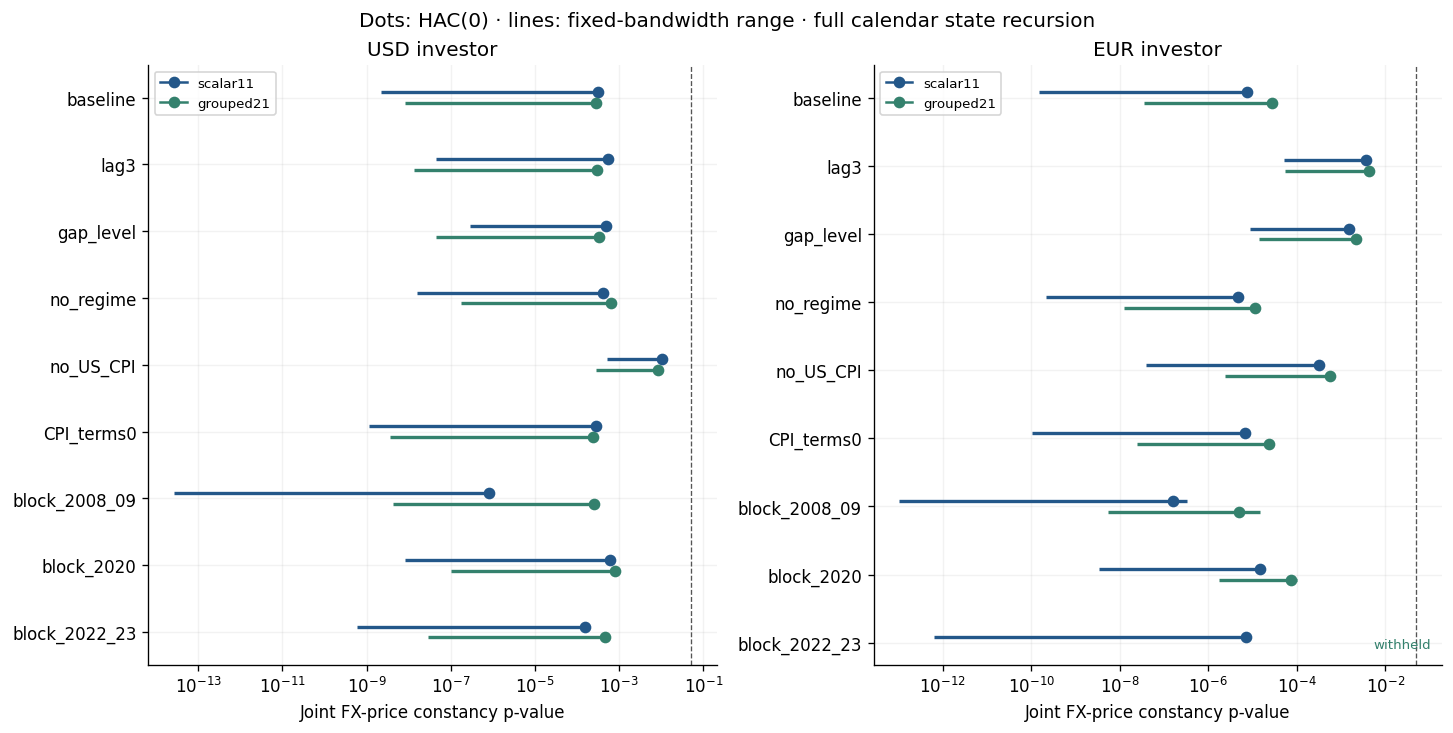

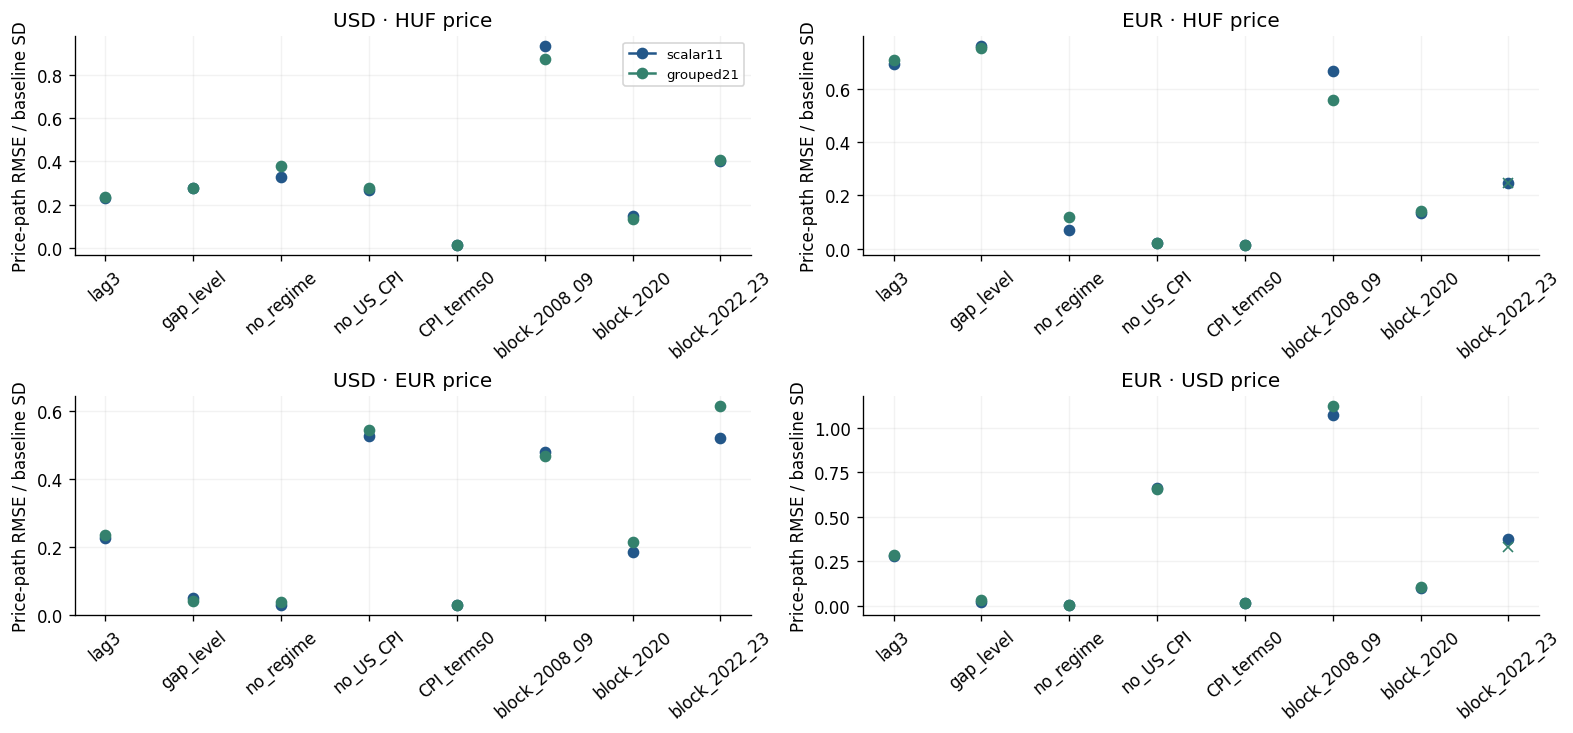

In [6]:
colors={"scalar11":"#235789","grouped21":"#34816d"}
fig,axes=plt.subplots(1,2,figsize=(12,6),layout="constrained",squeeze=False)
for ax,currency in zip(axes[0],["USD","EUR"]):
    for m,name in enumerate(COVARIANCE_MODELS):
        offset=.16*(m-(len(COVARIANCE_MODELS)-1)/2)
        for j,variant in enumerate(VARIANTS):
            key=f"{currency}_{name}_{variant}";p=tests.xs((key,"FX prices constant"),level=("case","test"))["robust_p_value"].reindex(HAC_LAGS)
            if p.notna().all():
                ax.hlines(j+offset,p.min(),p.max(),color=colors[name],lw=2)
                ax.plot(p.loc[0],j+offset,marker="o",color=colors[name],label=name if j==0 else None)
            else:ax.text(.98,j+offset,"withheld",transform=ax.get_yaxis_transform(),ha="right",fontsize=8,color=colors[name])
    ax.axvline(.05,color="#555555",lw=.8,ls="--");ax.set_xscale("log")
    ax.set(title=f"{currency} investor",xlabel="Joint FX-price constancy p-value",yticks=range(len(VARIANTS)),yticklabels=VARIANTS);ax.invert_yaxis();ax.legend(fontsize=8)
fig.suptitle("Dots: HAC(0) · lines: fixed-bandwidth range · full calendar state recursion")
plt.savefig(OUT/"01_joint_FX_robustness.png",dpi=160,bbox_inches="tight");plt.show();plt.close()
variants=[v for v in VARIANTS if v!="baseline"]
fig,axes=plt.subplots(2,2,figsize=(13,6),layout="constrained",squeeze=False)
for col,currency in enumerate(["USD","EUR"]):
    for row,label in enumerate(["H","O"]):
        ax=axes[row,col]
        for name in COVARIANCE_MODELS:
            for j,variant in enumerate(variants):
                key=f"{currency}_{name}_{variant}";ready=fit_summary.loc[key,"regular_all_lags"]
                ax.plot(j,path_comparison.loc[(key,label),"RMSE_over_baseline_SD"],marker="o" if ready else "x",color=colors[name],label=name if j==0 else None)
        other="EUR" if currency=="USD" else "USD"
        ax.set(title=f"{currency} · {('HUF' if label=='H' else other)} price",ylabel="Price-path RMSE / baseline SD",xticks=range(len(variants)),xticklabels=variants)
        ax.tick_params(axis="x",labelrotation=40)
axes[0,0].legend(fontsize=8)
plt.savefig(OUT/"02_price_path_sensitivity.png",dpi=160,bbox_inches="tight");plt.show();plt.close()

## 6. Save every check and the final summary

Retain baseline and all sensitivities, actual scoring weights, raw and weighted scores, full covariance
and fitted price paths, designs/normalizers/quality flags, residual diagnostics, component tests and
joint uncertainty. No p-value-based scenario selection is made. Different weights define different
objectives, so no across-check AIC/BIC ranking is reported. The broader covariance-targeting issue
and final research synthesis/release remain separate tasks.

In [7]:
tables={"summary.csv":summary,"fit_summary.csv":fit_summary,"restriction_tests.csv":tests,"price_coefficients.csv":coefficients,
    "design_audit.csv":design_audit,"inflation_audit.csv":inflation_audit,"instrument_normalizers.csv":normalizer_audit,"conditioning_quality.csv":quality_audit,
    "path_comparison.csv":path_comparison,"residual_diagnostics.csv":residuals,"cross_covariance_diagnostics.csv":cross_diagnostics,"starting_points.csv":starting_points}
for name,table in tables.items():table.to_csv(OUT/name)
for key,case in fits.items():
    f,inf=case["filter"],case["inference"]
    np.savez_compressed(OUT/f"parameters_{key}.npz",theta=case["theta"],weights=case["weights"],H=f["H"],mu=f["mu"],equity_alphas=np.zeros(3),residuals=f["errors"],scores_full=f["scores"],scores_weighted=inf["weighted_scores"],Hessian=inf["Hessian"],**{f"covariance_HAC{h}":v["covariance"] for h,v in inf["estimates"].items()})
    case["premia"].to_csv(OUT/f"Hungary_decomposition_{key}.csv")
    pd.DataFrame({"world":f["world_prices"],"HUF_FX":f["fx_prices"][:,0],"other_FX":f["fx_prices"][:,1],"HU_local":f["local_prices"],"US_local":f["prices"][1],"likelihood_weight":case["weights"]},index=data.index).to_csv(OUT/f"price_paths_{key}.csv")
    for label,z in case["pdesign"].items():pd.DataFrame(z,index=data.index,columns=case["columns"][label]).to_csv(OUT/f"design_{key}_{label}.csv")
record={"model_version":MODEL_VERSION,"snapshot":SNAPSHOT,"source_dataset_sha256":manifest["exports"]["dataset.csv"],"first":str(data.index[0]),"last":str(data.index[-1]),"state_observations":len(data),
    "covariance_models":COVARIANCE_MODELS,"variants":VARIANTS,"calendar_blocks":BLOCKS,"equity_alphas":"fixed zero","mean_model":"constant world/local; TV FX; corrected FX means",
    "objective_normalizer":"full T; zero/one weights retain full state recursion and calendar score spacing","HAC_lags":HAC_LAGS,"test_lags":TEST_LAGS,"SE_step_tolerance":SE_STEP_TOL,
    "engines":engine_hashes,"upstream":UPSTREAM,"upstream_file_sha256":upstream_hashes,"provenance_chain_sha256":chain_hashes,"raw_file_sha256":raw_hashes,
    "conditioning_root":str(conditioning_root.relative_to(ROOT)),"conditioning_file_sha256":conditioning_hashes,"US_annual_rate_carry_months":carry_limit,"python":platform.python_version(),"packages":versions}
(OUT/"estimation_manifest.json").write_text(json.dumps(record,indent=2,sort_keys=True)+"\n")
display(Markdown("**Final joint FX-price constancy summary — HAC(0)**"))
display(summary.pivot(index="variant",columns=["perspective","covariance"],values="FX_constancy_p_HAC0").reindex(VARIANTS))
display(Markdown("**Currency-specific constancy: Holm-adjusted within each two-currency family, HAC(0)**"))
display(summary[["HUF_constancy_holm_p_HAC0","other_constancy_holm_p_HAC0"]])
for currency in ["USD","EUR"]:
    for name in COVARIANCE_MODELS:
        q=summary[(summary["perspective"]==currency)&(summary["covariance"]==name)]
        complete=q["joint_test_complete"]&q["regular_all_lags"]
        stable=complete&q["FX_constancy_p_max"].lt(.05)
        display(Markdown(f"**{currency} · {name}:** joint FX constancy rejected at 5% for every fixed bandwidth in **{int(stable.sum())}/{len(q)}** reported cases, including baseline. "
            f"Complete regular cases: **{int(complete.sum())}/{len(q)}**. "
            "These are conditional sensitivity results, not independent replications."))
fragile=summary[(~summary["joint_test_complete"])|(~summary["regular_all_lags"])|summary["FX_constancy_p_max"].ge(.05)]
if len(fragile):
    display(Markdown("**Cases requiring qualification — non-rejection, bandwidth dependence or withheld inference**"));display(fragile)
display(Markdown("The calendar never skips a GARCH update. Zero-weight checks assess selected likelihood contributions; they do not erase crisis returns or all propagated CPI effects. "
    "The no-US-CPI check separately removes direct US-inflation conditioners. Gap-level results remain exploratory, and diagnostic/identification limitations remain visible. "
    f"Outputs: `{OUT.relative_to(ROOT)}`. Frozen source data and earlier outputs were not updated."))

**Final joint FX-price constancy summary — HAC(0)**

perspective           USD                     EUR            
covariance       scalar11   grouped21    scalar11   grouped21
variant                                                      
baseline      0.000316678 0.000280131 7.69171e-06 2.74192e-05
lag3          0.000531366 0.000304789   0.0037587  0.00426564
gap_level      0.00048525 0.000325938  0.00154243   0.0021974
no_regime     0.000414501 0.000656584  4.6579e-06 1.13278e-05
no_US_CPI        0.010149  0.00830937 0.000313868 0.000570743
CPI_terms0     0.00028345 0.000239812 6.85063e-06 2.41245e-05
block_2008_09   7.882e-07 0.000249909 1.61539e-07 5.03408e-06
block_2020    0.000594561 0.000814853 1.49378e-05 7.26039e-05
block_2022_23 0.000158435 0.000448594 7.29652e-06         NaN

**Currency-specific constancy: Holm-adjusted within each two-currency family, HAC(0)**

,HUF_constancy_holm_p_HAC0,other_constancy_holm_p_HAC0
case,,
USD_scalar11_baseline,0.0781585,0.0596175
USD_scalar11_lag3,0.112991,0.111646
USD_scalar11_gap_level,0.219632,0.219632
USD_scalar11_no_regime,0.127941,0.078757
USD_scalar11_no_US_CPI,0.287691,0.287691
USD_scalar11_CPI_terms0,0.0741275,0.0579452
USD_scalar11_block_2008_09,0.0761265,0.0308388
USD_scalar11_block_2020,0.0873251,0.0713346
USD_scalar11_block_2022_23,0.0505386,0.0505386


**USD · scalar11:** joint FX constancy rejected at 5% for every fixed bandwidth in **9/9** reported cases, including baseline. Complete regular cases: **9/9**. These are conditional sensitivity results, not independent replications.

**USD · grouped21:** joint FX constancy rejected at 5% for every fixed bandwidth in **9/9** reported cases, including baseline. Complete regular cases: **9/9**. These are conditional sensitivity results, not independent replications.

**EUR · scalar11:** joint FX constancy rejected at 5% for every fixed bandwidth in **9/9** reported cases, including baseline. Complete regular cases: **9/9**. These are conditional sensitivity results, not independent replications.

**EUR · grouped21:** joint FX constancy rejected at 5% for every fixed bandwidth in **8/9** reported cases, including baseline. Complete regular cases: **8/9**. These are conditional sensitivity results, not independent replications.

**Cases requiring qualification — non-rejection, bandwidth dependence or withheld inference**

,perspective,covariance,variant,state_months,scored_months,parameters,regular_all_lags,joint_test_complete,FX_constancy_p_HAC0,FX_constancy_p_min,FX_constancy_p_max,FX_zero_p_HAC0,HUF_constancy_holm_p_HAC0,other_constancy_holm_p_HAC0,variance_flags_full_path,cross_flags_full_path
case,,,,,,,,,,,,,,,,
EUR_grouped21_block_2022_23,EUR,grouped21,block_2022_23,321,297,38,False,False,NaN,NaN,NaN,NaN,NaN,NaN,0,0


The calendar never skips a GARCH update. Zero-weight checks assess selected likelihood contributions; they do not erase crisis returns or all propagated CPI effects. The no-US-CPI check separately removes direct US-inflation conditioners. Gap-level results remain exploratory, and diagnostic/identification limitations remain visible. Outputs: `output/14_FX_targeted_robustness/fixed_2026-11-13/2000-01_2026-09/targeted_set`. Frozen source data and earlier outputs were not updated.

## Reading the recorded frozen run

These findings describe the default nine-case set above, including baseline; they are not a claim about every possible specification.

- **Joint FX time variation survives the targeted checks:** all **35 regular cases** reject joint FX-price constancy at 5% for every fixed HAC bandwidth. Removing direct US-CPI predictors weakens the USD evidence most: HAC(0) p-values become **0.0101 (scalar)** and **0.00831 (grouped)**.
- **Separate HUF evidence is sensitive.** In the USD baseline, the two-block Holm-adjusted HUF constancy p-values are **0.0782 / 0.0673** at HAC(0), so the strong joint result does not establish each price separately. For EUR, the HUF constancy test stops rejecting at every bandwidth under both `lag3` and `gap_level`; the other currency's USD-price constancy test still rejects. The persistent gap-level check remains exploratory.
- **One case has withheld inference:** EUR `grouped21` with 2022–23 likelihood terms zeroed reaches the lower numerical bound on the world/US second-shock-lag logit (parameter position 30, zero-based). Keep its point fit visible, but do not count its missing p-values as a non-rejection or a valid rejection.

Full-path residual flags and fitted-price changes remain relevant even when a joint test rejects. The calendar-block checks retain observed returns and every GARCH update; they are influence checks. The next research tasks are the covariance-targeting sensitivity and the final synthesis/reproducibility package.